# Google Play Store Apps Data Analysis

## Research Question and Project Objective:-
-How do app ratings (`Rating`) and installation counts (`Installs`) differ across app categories (`Category`) and pricing types (`Type`: Free vs. Paid) on the Google Play Store?

The objective of this project is to load real Google Play Store data from Kaggle, inspect data structure and data quality, clean and transform key columns, aggregate performance metrics, build at least three purposeful visualizations with written interpretations, and publish a reproducible workflow on GitHub.

## Dataset Source and Reproducibility:-
-This project uses the **Google Play Store Apps** dataset (`googleplaystore.csv`) from **Kaggle**. To ensure reproducibility across devices without hard-coded local paths, the notebook checks for a local copy first, downloads from the repository raw URL when set, and falls back to an interactive upload prompt in Google Colab if needed.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")

FILE_NAME = "googleplaystore.csv"
RAW_DATA_URL = "https://raw.githubusercontent.com/21Raghad/google-play-store-analysis/refs/heads/main/data/googleplaystore.csv"

if not os.path.exists(FILE_NAME) and RAW_DATA_URL:
  try:
    temp_df = pd.read_csv(RAW_DATA_URL)
    temp_df.to_csv(FILE_NAME, index=False)
  except Exception:
    pass

if not os.path.exists(FILE_NAME):
  try:
    from google.colab import files

    uploaded = files.upload()
    if uploaded:
      FILE_NAME = list(uploaded.keys())[0]
  except ImportError:
    pass

df = pd.read_csv(FILE_NAME)
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## 1. Data Understanding:-
In this section, we inspect the dataset shape, column names, data types, missing values, and basic descriptive statistics to assess data quality prior to cleaning.

In [3]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)
df.info()

missing_df = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().sum() / len(df) * 100).round(2),
})
print(missing_df[missing_df["missing_count"] > 0])

print(df.describe(include="all"))

(10841, 13)
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']
App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs           object
Type               object
Price              object
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type      

**Initial Data Quality Notes**
- The dataset contains missing values in specific columns (such as `Rating`) that must be evaluated and handled during cleaning.
- Columns representing numeric quantities (`Installs` and `Price`) include formatting symbols (`+`, `,`, `$`) or non-numeric strings and require type conversion before numerical analysis.
- Duplicate records and inconsistent or invalid entries may be present and should be inspected and removed before transformation and aggregation.

## 2. Data Cleaning and Preparation:-
In this section, we clean duplicate and invalid records, standardize numeric columns (`Installs`, `Price`, `Rating`), apply data transformation (`Install_Tier`) and data aggregation (category and pricing summary), and save the final analysis-ready dataset.

In [4]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
df_clean["Reviews"] = pd.to_numeric(df_clean["Reviews"], errors="coerce")
df_clean = df_clean.sort_values("Reviews", ascending=False).drop_duplicates(subset="App")

if "Category" in df_clean.columns:
  df_clean = df_clean[df_clean["Category"] != "1.9"].copy()

if "Installs" in df_clean.columns:
  df_clean["Installs"] = (
      df_clean["Installs"]
      .astype(str)
      .str.replace("+", "", regex=False)
      .str.replace(",", "", regex=False)
  )
  df_clean["Installs"] = pd.to_numeric(df_clean["Installs"], errors="coerce")

if "Price" in df_clean.columns:
  df_clean["Price"] = (
      df_clean["Price"].astype(str).str.replace("$", "", regex=False)
  )
  df_clean["Price"] = pd.to_numeric(df_clean["Price"], errors="coerce")

if "Rating" in df_clean.columns:
  df_clean["Rating"] = pd.to_numeric(df_clean["Rating"], errors="coerce")
  rating_median = df_clean["Rating"].median()
  df_clean["Rating"] = df_clean["Rating"].fillna(rating_median)

df_clean = df_clean.dropna(subset=["Installs", "Price", "Category", "Type"])
print(df_clean.shape)
print(df_clean.isnull().sum())

(9658, 13)
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       8
Android Ver       2
dtype: int64


In [5]:
df_clean["Install_Tier"] = pd.cut(
    df_clean["Installs"],
    bins=[-1, 10000, 1000000, float("inf")],
    labels=["Low", "Medium", "High"],
)

print(df_clean[["App", "Category", "Type", "Installs", "Install_Tier"]].head())
print(df_clean["Install_Tier"].value_counts())

                                           App       Category  Type  \
2544                                  Facebook         SOCIAL  Free   
336                         WhatsApp Messenger  COMMUNICATION  Free   
2604                                 Instagram         SOCIAL  Free   
382   Messenger – Text and Video Chat for Free  COMMUNICATION  Free   
1879                            Clash of Clans           GAME  Free   

        Installs Install_Tier  
2544  1000000000         High  
336   1000000000         High  
2604  1000000000         High  
382   1000000000         High  
1879   100000000         High  
Install_Tier
Low       4174
Medium    3503
High      1981
Name: count, dtype: int64


In [6]:
category_summary = (
    df_clean.groupby(["Category", "Type"], observed=False)
    .agg(
        App_Count=("App", "count"),
        Avg_Rating=("Rating", "mean"),
        Total_Installs=("Installs", "sum"),
    )
    .reset_index()
)

category_summary["Avg_Rating"] = category_summary["Avg_Rating"].round(2)
category_summary = category_summary.sort_values(
    by="Total_Installs", ascending=False
)
print(category_summary.head(10))

              Category  Type  App_Count  Avg_Rating  Total_Installs
26                GAME  Free        864        4.24     13436924450
10       COMMUNICATION  Free        288        4.16     11036916201
55               TOOLS  Free        751        4.06      8101044474
20              FAMILY  Free       1690        4.19      6205391691
47        PRODUCTIVITY  Free        346        4.20      5791679314
51              SOCIAL  Free        236        4.26      5487861902
45         PHOTOGRAPHY  Free        262        4.17      4656268915
59       VIDEO_PLAYERS  Free        160        4.07      3931831720
57    TRAVEL_AND_LOCAL  Free        207        4.10      2894704086
39  NEWS_AND_MAGAZINES  Free        252        4.15      2369212260


In [7]:
output_file = "googleplaystore_cleaned.csv"
df_clean.to_csv(output_file, index=False)
print(output_file)

googleplaystore_cleaned.csv


**Data Preparation Notes**
- Removed duplicate rows and invalid entries (`Category == '1.9'`) to prevent distortion in group summaries.
- Cleaned formatting symbols (`+`, `,`, `$`) from `Installs` and `Price`, converted numeric fields properly, and imputed missing `Rating` values using the median to limit outlier influence.
- Applied **Transformation** (`Install_Tier`) and **Aggregation** (`groupby` by `Category` and `Type`), then saved the final dataset to `googleplaystore_cleaned.csv`.

## 3. Data Analysis, Visualizations, and Interpretations:-
In this section, we analyze the cleaned Google Play Store dataset and create three purposeful visualizations with clear titles, labeled axes, and written interpretations addressing our research question.

In [8]:
type_summary = (
    df_clean.groupby("Type", observed=False)
    .agg(
        App_Count=("App", "count"),
        Mean_Rating=("Rating", "mean"),
        Median_Rating=("Rating", "median"),
        Total_Installs=("Installs", "sum"),
        Mean_Installs=("Installs", "mean"),
    )
    .reset_index()
)

type_summary["Mean_Rating"] = type_summary["Mean_Rating"].round(2)
type_summary["Mean_Installs"] = type_summary["Mean_Installs"].round(0)
display(type_summary)

top_categories = (
    df_clean.groupby("Category", observed=False)["Installs"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
display(top_categories)

,Type,App_Count,Mean_Rating,Median_Rating,Total_Installs,Mean_Installs
0,Free,8904,4.19,4.3,75265162646,8452961.0
1,Paid,754,4.27,4.3,57363781,76079.0


,Category,Installs
0,GAME,13457924415
1,COMMUNICATION,11038276251
2,TOOLS,8102771915
3,FAMILY,6226541505
4,PRODUCTIVITY,5793091369
5,SOCIAL,5487867902
6,PHOTOGRAPHY,4658147655
7,VIDEO_PLAYERS,3931902720
8,TRAVEL_AND_LOCAL,2894887146
9,NEWS_AND_MAGAZINES,2369217760


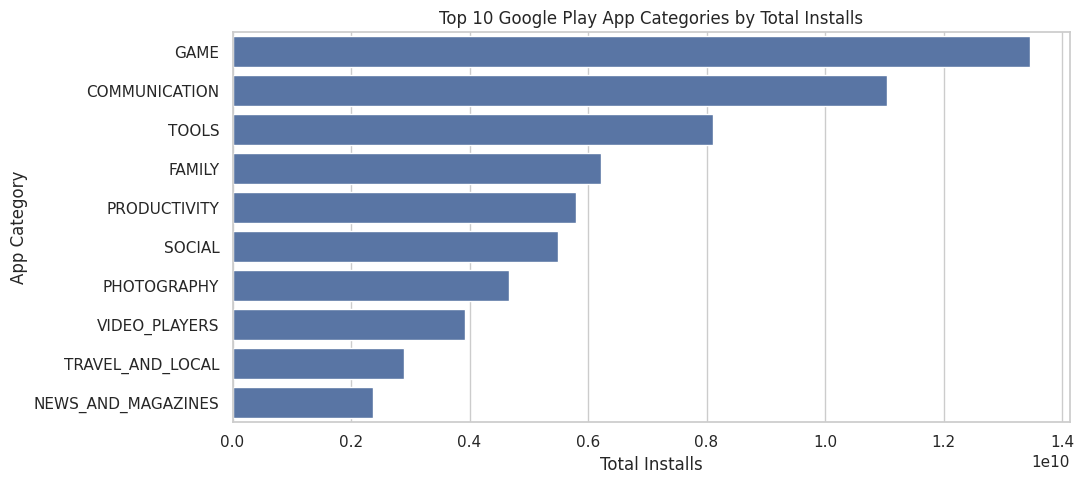

In [9]:
plt.figure(figsize=(11, 5))
sns.barplot(data=top_categories, x="Installs", y="Category")
plt.title("Top 10 Google Play App Categories by Total Installs")
plt.xlabel("Total Installs")
plt.ylabel("App Category")
plt.tight_layout()
plt.show()

**Visualization 1 Interpretation**

The horizontal bar chart shows total installation volume across the top 10 Google Play categories. Categories with broad consumer demand and high user engagement account for the largest share of installs, highlighting where user adoption is most concentrated across the store.

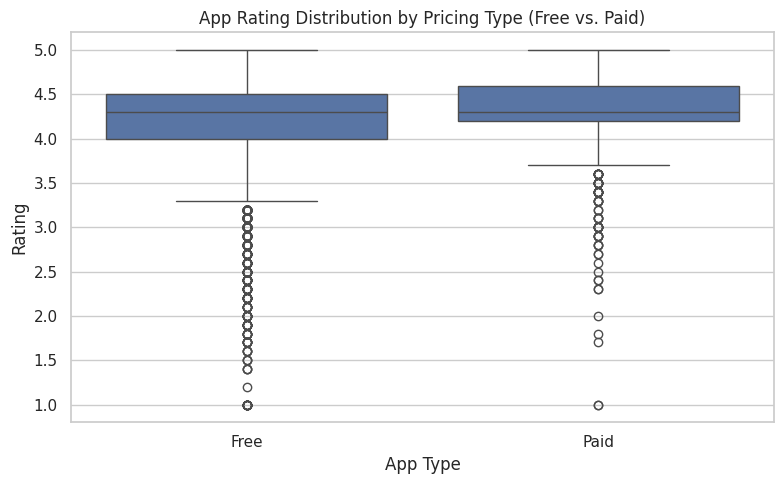

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Type", y="Rating")
plt.title("App Rating Distribution by Pricing Type (Free vs. Paid)")
plt.xlabel("App Type")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

**Visualization 2 Interpretation**

The box plot compares rating distributions between Free and Paid apps. Both pricing models cluster around high rating values, while outliers appear toward lower ratings, indicating that pricing alone does not guarantee higher or lower ratings without considering app quality and user expectations.

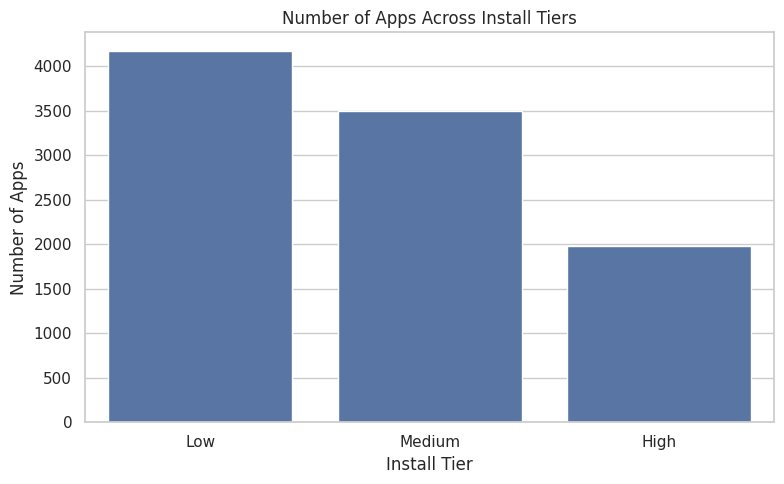

In [11]:
tier_counts = df_clean["Install_Tier"].value_counts().reset_index()
tier_counts.columns = ["Install_Tier", "App_Count"]

plt.figure(figsize=(8, 5))
sns.barplot(data=tier_counts, x="Install_Tier", y="App_Count")
plt.title("Number of Apps Across Install Tiers")
plt.xlabel("Install Tier")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

**Visualization 3 Interpretation**

The bar chart summarizes how apps are distributed across Low, Medium, and High install tiers after transformation. Most apps fall into specific volume tiers rather than reaching extreme download counts uniformly, illustrating long-tail behavior in app store adoption.

## 4. Results, Conclusions, and Limitations:-

**Key Results and Conclusions**
- Cleaning and standardizing numeric fields (`Installs`, `Price`, `Rating`) alongside transformation (`Install_Tier`) and aggregation (`Category` and `Type`) enabled reliable comparison of app performance.
- Install volume varies strongly across categories and tiers, while rating distributions across Free and Paid apps share similar central tendencies with lower-rating outliers.

**Limitations**
- The dataset represents a historical snapshot from Kaggle and may not reflect current Google Play Store rankings, updates, or policy changes.
- Missing `Rating` values were imputed using the median and certain formatting anomalies were removed, which may slightly shift aggregate figures.
- Install counts in the dataset are reported as bracketed thresholds rather than exact live download figures.